# Лабораторная работа №7 Классификация

## Импорты и константы

In [277]:
import re
from pathlib import Path
import json

import numpy as np
import pandas as pd

from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder, MinMaxScaler
from sklearn.model_selection import train_test_split
from imblearn.over_sampling import SMOTENC

from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import precision_score, recall_score, f1_score

import seaborn as sns
import matplotlib.pyplot as plt

In [278]:
BASE_DIR = Path.cwd()
DATA_DIR = BASE_DIR / 'data'
DF_PATH = DATA_DIR / 'База.csv'

RANDOM_STATE = 42

pd.set_option('display.max_columns', None)

## Основная часть

В этом задании дан датасет с реальными данными одной строительной компании о бронированиях на покупку недвижимости. 

Бронирование может привести к заключению договора на покупку, а может быть отменено. 

Для  планирования  своих  финансовых  показателей  компания  хочет прогнозировать, приведет ли бронирование к заключению договора или нет. 

Таким  образом,  вам  предстоит  построить  модель  для  бинарной  классификации бронирований. 

В этом задании будем работать только с жилой недвижимостью, поскольку именно по ней имеется больше всего данных. 

### 1.  Загрузите данные из файла "база.csv".  Столбцы (признаки) имеют следующий смысл:

`УИД_Брони`  –  уникальный идентификатор брони  (для классификации его использовать не надо – это просто id)

`ДатаБрони` – дата установления брони

`ВремяБрони` – время установления брони (GMT+4)

`ИсточникБрони` – способ оформления брони: МП — мобильное приложение, ручная — офис продаж (бинарный признак)

`ВременнаяБронь`  –  подтвержденная заявка на бронь(«Нет») или  заявка на бронь не подтверждена отделом продаж («Да») (бинарный признак) 

`СледующийСтатус` – если  пусто или  «В  резерве» — статус  еще не определен, «Продана» — договор оформлен, «Свободна» — бронь снята (отменена). *Это и есть целевой признак, который нужно научиться предсказывать*

`Город` – город проекта

`ВидПомещения` – один из 4 видов: жилые помещения, нежилые помещения, кладовые,  паркинг.  Нас  будут  интересовать  бронирования  только  со значением этого признака «жилые помещения».

`Тип`  –  количество комнат для жилых помещений (для остальных видов неактуально)

`ПродаваемаяПлощадь` – общая продаваемая площадь помещения

`Этаж` – этаж расположения помещения

`СтоимостьНаДатуБрони` – актуальная  стоимость  по  прайсу  на  дату установления брони

`ТипСтоимости` – «Стоимость  при  100%  оплате»  или  «Стоимость  в рассрочку»,  остальные  варианты  можно  считать  отсутствием  значения (бинарный признак)

`ВариантОплаты` – «Единовременная  оплата»  или  «Оплата  в рассрочку» (бинарный признак)

`ВариантОплатыДоп` – уточненный вариант оплаты: Ипотека/Вторичное жилье, если "пусто" — использовать ВариантОплаты

`СкидкаНаКвартиру` – размер  предоставленной  скидки  при  её  наличии, отрицательное значение —  это наценка на помещение (как правило, при выводе из закрытого ассортимента)

`ФактическаяСтоимостьПомещения` – стоимость  заключения  сделки (стоимость на дату брони за вычетом скидки)

`СделкаАН` – участие в сделке агентства недвижимости (да/нет) (бинарный признак)

`ИнвестиционныйПродукт` – да/нет  — признак  продажи  помещения  по инвестиционному договору (бинарный признак)

`Привилегия` – да/нет — признак продажи помещения по инвестиционному договору типа Привилегия (бинарный признак)

`Статус лида (из CRM)`  –  Статус клиента: S -  успешный, P -  в работе, F - забракованный

In [279]:
df = pd.read_csv(DF_PATH, sep=';', encoding='cp1251')

In [280]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5519 entries, 0 to 5518
Data columns (total 21 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   УИД_Брони                      5519 non-null   str    
 1   ДатаБрони                      5519 non-null   str    
 2   ВремяБрони                     5519 non-null   str    
 3   ИсточникБрони                  5519 non-null   str    
 4   ВременнаяБронь                 5519 non-null   str    
 5   СледующийСтатус                5411 non-null   str    
 6   Город                          5512 non-null   str    
 7   ВидПомещения                   5427 non-null   str    
 8   Тип                            5320 non-null   str    
 9   ПродаваемаяПлощадь             5318 non-null   str    
 10  Этаж                           4771 non-null   float64
 11  СтоимостьНаДатуБрони           5519 non-null   str    
 12  ТипСтоимости                   5519 non-null   str    
 13 

### 2.  Предварительная фильтрация. 

- a. Поскольку  нас  интересуют  только  сделки  с  жилой  недвижимостью, отфильтруйте данные, оставив только те, для которых «ВидПомещения» = «жилые помещения».

В дальнейшем этот столбец использоваться не будет, его можно удалить (или удалите его из датасета вообще, или просто нигде далее не рассматривайте).

---

Отфильтрую данные по категории `жилые помещения` признака `ВидПомещения` отбросив другие категории и исключив пропуски в данном столбце.

Удалю данный столбец, поскольку он будет принимать единственное значение.

In [281]:
df['ВидПомещения'].unique()

<StringArray>
['жилые помещения', 'кладовые', 'нежилые помещения', 'паркинг', nan]
Length: 5, dtype: str

In [282]:
df['ВидПомещения'].isna().sum()

np.int64(92)

In [283]:
df = df[df['ВидПомещения'] == 'жилые помещения']

In [284]:
df = df.drop(columns=['ВидПомещения'])

- b. Также  для  нас  бесполезны  данные,  по  которым  статус  не  определен. 

Отфильтруйте  данные  по  признаку  «СледующийСтатус».  В  оставшихся строчках замените значение «Продана» на 1, «Свободна» – на 0. 

In [285]:
df['СледующийСтатус'].unique()

<StringArray>
['Свободна', 'Продана', nan, 'В резерве']
Length: 4, dtype: str

In [286]:
df = df[df['СледующийСтатус'].isin(['Продана', 'Свободна'])]

In [287]:
ns_label2ns_id = {
    'Продана': 1,
    'Свободна': 0
}

In [288]:
df['СледующийСтатус'] = df['СледующийСтатус'].map(ns_label2ns_id)

- c. Не забывайте, что столбец «УИД_Брони» для нас также не представляет интереса –  удалите его из датасета вообще, или просто нигде далее не рассматривайте.

In [289]:
df = df.drop(columns=['УИД_Брони'])

### 3.  Проверьте тип данных и преобразуйте все данные к числовому типу. 

- a. Для  тех  полей,  которые  по  смыслу  являются  числовыми  (например, «ПродаваемаяПлощадь») – просто проверьте правильность типа.

---

По смыслу являются числовыми поля: `ПродаваемаяПлощадь`, `Этаж`, `СтоимостьНаДатуБрони`, `СкидкаНаКвартиру`, `ФактическаяСтоимостьПомещения`

Поле `Тип` будет рассмотрен ниже

In [290]:
def prep_num_cols(df: pd.DataFrame) -> pd.DataFrame:
    df['ПродаваемаяПлощадь'] = df['ПродаваемаяПлощадь'].str.replace(',', '.')
    df['ПродаваемаяПлощадь'] = df['ПродаваемаяПлощадь'].astype(float)
    df['Этаж'] = df['Этаж'].astype(int)
    df['СтоимостьНаДатуБрони'] = df['СтоимостьНаДатуБрони'].str.replace(',', '.')
    df['СтоимостьНаДатуБрони'] = df['СтоимостьНаДатуБрони'].astype(float)
    df['ФактическаяСтоимостьПомещения'] = df['ФактическаяСтоимостьПомещения'].str.replace(',', '.')
    df['ФактическаяСтоимостьПомещения'] = df['ФактическаяСтоимостьПомещения'].astype(float)
    return df

In [291]:
df = prep_num_cols(df)

СкидкаНаКвартиру может быть при Nan - 0, а может быть случайно не записана.

Проверю это предположение:

In [292]:
# ФактическаяСтоимостьПомещения и СтоимостьНаДатуБрони без пропусков
ind = df[df['СкидкаНаКвартиру'].isna() & df['ФактическаяСтоимостьПомещения'] - df['СтоимостьНаДатуБрони'] != 0].index
df.loc[ind, ['СтоимостьНаДатуБрони', 'СкидкаНаКвартиру', 'ФактическаяСтоимостьПомещения']]

,СтоимостьНаДатуБрони,СкидкаНаКвартиру,ФактическаяСтоимостьПомещения
5324,2964600.0,NaN,3023892.0


Нашли единственную строку с пропущенной ненулевой скидкой (c наценкой)

Согласовано с формой записи скидки, заполню пропуски:
- отрицательное значение - наценка,
- положительное значение - скидка.

In [293]:
df['СкидкаНаКвартиру'] = df['СкидкаНаКвартиру'].str.replace(',', '.')
df['СкидкаНаКвартиру'] = df['СкидкаНаКвартиру'].astype(float)
df['СкидкаНаКвартиру'] = df['СкидкаНаКвартиру'].fillna(df['СтоимостьНаДатуБрони'] - df['ФактическаяСтоимостьПомещения'])

In [294]:
df.loc[ind, ['СтоимостьНаДатуБрони', 'СкидкаНаКвартиру', 'ФактическаяСтоимостьПомещения']]

,СтоимостьНаДатуБрони,СкидкаНаКвартиру,ФактическаяСтоимостьПомещения
5324,2964600.0,-59292.0,3023892.0


- b. Для  бинарных  признаков  (например,  «ИсточникБрони»)  выполните кодирование (один вариант закодируйте 0, другой 1).

---

Бинарные признаки: `ИсточникБрони`, `ВременнаяБронь`, `ТипСтоимости`, `ВариантОплаты`, `СделкаАН`, `ИнвестиционныйПродукт`, `Привилегия`.

Перед кодированием признака `ВариантОплаты` необходимо передать значение в пропуск столбца `ВариантОплатыДоп` (данный признак будет закодирован OHE)

In [295]:
def prep_cat_bin_cols(df: pd.DataFrame) -> tuple[dict[str, OrdinalEncoder], pd.DataFrame]:
    df['ВариантОплатыДоп'] = df['ВариантОплатыДоп'].fillna(df['ВариантОплаты'])
    col_oe = {}
    for col in ['ИсточникБрони', 'ВременнаяБронь', 'ТипСтоимости', 'ВариантОплаты', 'СделкаАН', 'ИнвестиционныйПродукт', 'Привилегия']:
        # Уберем для fit пропущенные значения
        # при transform, за счет
        # handle_unknown='use_encoded_value' и 
        # unknown_value=np.nan
        # будет присваивать неизвестным nan
        oe = OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=np.nan) # использую вместо LabelEncoder тк позволяет игнорировать* nan при transform
        oe.fit(df[df[col].notna()][[col]])
        df[col] = oe.transform(df[[col]])
        col_oe[col] = oe
    return col_oe, df

In [296]:
col_oe, df = prep_cat_bin_cols(df)

- c. Для  категориальных  не  бинарных  признаков  (например,  «Город») выполните one-hot кодирование.

---

К не бинарным категориальным признакам относятся: `Город`, `ВариантОплатыДоп`, `Статус лида (из CRM)`

In [297]:
def prep_cat_cols(df: pd.DataFrame) -> tuple[dict[str, OneHotEncoder], pd.DataFrame]:
    col_ohe = {}
    for col in ['Город', 'ВариантОплатыДоп', 'Статус лида (из CRM)']:
        ohe = OneHotEncoder(handle_unknown='ignore', sparse_output=False)
        # Уберем для fit пропущенные значения
        # при transform, за счет handle_unknown='ignore'
        # будет считать nan за неизвестную категорию
        # и присваивать 0 всем категориям
        ohe.fit(df[df[col].notna()][[col]])
        encoded_col = ohe.transform(df[[col]])
        encoded_col_df = pd.DataFrame(
            encoded_col,
            columns=ohe.get_feature_names_out([col]),
            index=df.index
        )
        df = df.drop(columns=[col])
        df = pd.concat([df, encoded_col_df], axis=1)
        col_ohe[col] = ohe
    return col_ohe, df

In [298]:
col_ohe, df = prep_cat_cols(df)

- d. Обратите внимание на поле «Тип»

По смыслу оно числовое (количество комнат), но напрямую сконвертировать его в числовой тип мешает буковка «к» в конце.

Напишите вручную преобразование, которое удаляет букву «к» в конце и конвертирует то, что осталось, в число. Если это невозможно (среди данных вам встретится еще вариант, когда в этом поле записано просто «с») – просто пока оставьте поле пустым (NaN).

---

Для преобразования типа поля `Тип` в числовое, студиям (с) присвою значение 0, чтобы не смешивать их с пропущенными значеними

In [299]:
df['Тип'].unique()

<StringArray>
['2,5к', '3,5к', '1,5к', '2к', '3к', '1к', 'с', '4,5к', '4к', nan]
Length: 10, dtype: str

In [300]:
def convert_col_type(x: str) -> float:
    if pd.isna(x):
        return np.nan
    x = re.sub(r'[кс]', '', x)
    if not x:
        return 0.
    x = x.replace(',', '.')
    return float(x)

In [301]:
df['Тип'] = df['Тип'].apply(convert_col_type)

In [302]:
df['Тип'].unique()

array([2.5, 3.5, 1.5, 2. , 3. , 1. , 0. , 4.5, 4. , nan])

Поля (кроме ДатаБрони и ВремяБрони) приведены к числовому типу

In [303]:
df.info()

<class 'pandas.DataFrame'>
Index: 3944 entries, 0 to 5518
Data columns (total 32 columns):
 #   Column                                  Non-Null Count  Dtype  
---  ------                                  --------------  -----  
 0   ДатаБрони                               3944 non-null   str    
 1   ВремяБрони                              3944 non-null   str    
 2   ИсточникБрони                           3944 non-null   float64
 3   ВременнаяБронь                          3944 non-null   float64
 4   СледующийСтатус                         3944 non-null   int64  
 5   Тип                                     3900 non-null   float64
 6   ПродаваемаяПлощадь                      3900 non-null   float64
 7   Этаж                                    3944 non-null   int64  
 8   СтоимостьНаДатуБрони                    3944 non-null   float64
 9   ТипСтоимости                            3944 non-null   float64
 10  ВариантОплаты                           3941 non-null   float64
 11  СкидкаН

### 4.  Проверьте, есть ли по каким-либо признакам отсутствующие данные.

- a. Отсутствующие  данные в поле «СкидкаНаКвартиру» замените на 0 (это значение по умолчанию –  если поле не заполнено, то скидки, по всей видимости, нет).

---

Заменил на этапе преобразования к числовому типу

- b. Отсутствующие данные в полях «Тип» и «ПродаваемаяПлощадь» замените на медианное значение, вычисленное по всему набору данных

(признаки кажутся достаточно важными, поэтому удалять эти столбцы не хочется; пустых значений довольно много, поэтому удалять строки тоже не очень хорошо; какого-то значения «по умолчанию» для этих полей нет; поэтому заменить эти значения на медиану представляется наилучшим решением). 

In [304]:
median_type = df['Тип'].median(skipna=True)
median_area_sale = df['ПродаваемаяПлощадь'].median(skipna=True)

df['Тип'] = df['Тип'].fillna(median_type)
df['ПродаваемаяПлощадь'] = df['ПродаваемаяПлощадь'].fillna(median_area_sale)

print(f'Медиана "Тип": {median_type}\nМедиана "ПродаваемаяПлощадь": {median_area_sale}')

Медиана "Тип": 2.0
Медиана "ПродаваемаяПлощадь": 60.5


- c. Что делать с полем «ВариантОплатыДоп» решите самостоятельно (можно, как указано в описании, вместо пустых значений использовать значение из поля «ВариантОплаты», но в таком случае обратите внимание, что признак становится не бинарным; допустимо также совсем убрать этот столбец из рассмотрения).

---

Пустые значения признака `ВаприантОплатыДоп` были заполнены значениями поля `ВариантОплаты`, поэтому `ВариантОплатыДоп` кодировался при помощи `OneHotEncoder` (не бинарный признак).

Однако были примеры заполнения None -> None. Метод fit кодировщика OHE был применен к данным без пропусков, метод transform кодирует известные признаки, при неизвестных расставляет везде 0 (в т.ч. пропуски).

- d. По  всем  остальным  полям  примите  решение  самостоятельно.  Если отсутствующих данных не много, то удалите соответствующие строки.

---

Осталить пропуски в столбце `ВариантОплаты` (бинарный признак). Заменил их модой.

In [305]:
df.isna().sum().sort_values(ascending=False).loc[lambda x: x > 0]

ВариантОплаты    3
dtype: int64

In [306]:
moda_pay_option = df['ВариантОплаты'].mode(dropna=True)[0]

df['ВариантОплаты'] = df['ВариантОплаты'].fillna(moda_pay_option)

print(f'Медиана "ВариантОплаты": {moda_pay_option} ({col_oe['ВариантОплаты'].inverse_transform([[moda_pay_option]])})')

Медиана "ВариантОплаты": 0.0 ([['Единовременная оплата']])


### 5.  Дополнение данных.

Комментарий.

Многие алгоритмы классификации, по сути, учитывают только 
линейную зависимость.

Поэтому, несмотря на то что добавляемые признаки 
полностью определяются значениями других признаков, их добавление имеет 
смысл – их зависимость от других признаков не линейная.

- a. Добавьте  новый  признак  «Цена  за  квадратный  метр».  Он  должен вычисляться  на  основе  значений  признаков «ФактическаяСтоимостьПомещения» и «ПродаваемаяПлощадь».

In [307]:
df['ЦенаЗаКвадратныйМетр'] = df['ФактическаяСтоимостьПомещения'] / df['ПродаваемаяПлощадь']

- b. Добавьте  новый  признак  «Скидка  в  процентах»,  на  основе  значений «ФактическаяСтоимостьПомещения» и «СкидкаНаКвартиру».

In [308]:
df['СкидкаВПроцентах'] = df['СкидкаНаКвартиру'] / df['ФактическаяСтоимостьПомещения']

- поля ДатаБрони и ВремяБрони

Извлеку информацию из данных признаков:

[-] можно соединить два признака и перобразовать в Unix-время в миллисекундах, но данное перобразование считаю не подходящим для решения текущей задачи.

[+] допускаю, что большую ценность принесут `день` и `месяц` из `ДатаБрони` и `час` из `ВремяБрони`.

Почитал, что можно применить циклическое кодирование для извлеченных признаков (день, месяц, час). Пока оставлю в исходном виде. 

In [309]:
df['ДатаБрони'] = pd.to_datetime(df['ДатаБрони'], format='%d.%m.%Y')
df['ВремяБрони'] = pd.to_datetime(df['ВремяБрони'], format='%H:%M:%S')

In [310]:
df['ДеньБрони'] = df['ДатаБрони'].dt.day
df['МесяцБрони'] = df['ДатаБрони'].dt.month
df['ЧасБрони'] = df['ВремяБрони'].dt.hour

In [311]:
df = df.drop(columns=['ДатаБрони', 'ВремяБрони'])

### 6.  Выполните  нормализацию.

Можете  самостоятельно  выбрать  способ нормализации.  «По  умолчанию»  предлагается  выполнить  минимаксную нормализацию  и  привести  все  значения  к  диапазону  [0;1],  кроме  признака «СкидкаНаКвартиру» - его логичнее приводить к диапазону [-0,5; 0,5].

In [312]:
scaler_0_1 = MinMaxScaler()
cols_0_1 = ['Тип', 'ПродаваемаяПлощадь', 'Этаж', 'СтоимостьНаДатуБрони', 
            'СкидкаНаКвартиру', 'ФактическаяСтоимостьПомещения', 'ЦенаЗаКвадратныйМетр',
            'ДеньБрони', 'МесяцБрони', 'ЧасБрони']
# применю fit и transform после разделения на train и test

In [313]:
scaler_5_5 = MinMaxScaler(feature_range=(-.5, .5))
cols_5_5 = ['СкидкаНаКвартиру', 'СкидкаВПроцентах']
# применю fit и transform после разделения на train и test

### 7.  Проверьте  датасет  на  сбалансированность 

(количество  строк  со  значением целевого признака 0 и со значением 1). Является ли датасет сбалансированным? 

---

Датасет не сбалансирован, *Проданых* квартир намного меньше *Свободных*.

Во время обучения и инференса модели дисбаланс классов может существенно повлиять на качество: модель будет хуже предсказывать меньший класс.

Для этого применю `Oversampling` для восполнения недостающего класса в train выборке

In [314]:
df.groupby('СледующийСтатус').agg(count=('СледующийСтатус', 'count'), percent=('СледующийСтатус', lambda x: x.count() / len(df) * 100))

,count,percent
СледующийСтатус,,
0,2804,71.095335
1,1140,28.904665


### 8.  Сформируйте список факторных признаков и целевой признак. 

In [315]:
X = df.drop(columns=['СледующийСтатус'])
y = df['СледующийСтатус']

### 9.  Выполните  разбиение  датасета  на  обучающую  и  тестовую  выборки. 

При формировании обучающей и тестовой выборок строки из исходного датафрейма должны выбираться в случайном порядке. 

In [316]:
# Разбиение на train и test
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=RANDOM_STATE, stratify=y, test_size=0.2, shuffle=True)
# Масштабирование train
X_train[cols_0_1] = scaler_0_1.fit_transform(X_train[cols_0_1])
X_train[cols_5_5] = scaler_5_5.fit_transform(X_train[cols_5_5])
# Масштабирование test
X_test[cols_0_1] = scaler_0_1.transform(X_test[cols_0_1])
X_test[cols_5_5] = scaler_5_5.transform(X_test[cols_5_5])
# Поскольку cols_0_1 и cols_5_5 - числовые признаки
# уберу их и получу категориальные
cat_cols = X_train.columns.difference(cols_0_1 + cols_5_5)
# индекс столбцов с категориальными данными
cat_cols_idx = [X_train.columns.get_loc(col) for col in cat_cols]
# Oversampling
smotenc = SMOTENC(categorical_features=cat_cols_idx, random_state=RANDOM_STATE)
X_train_resampled, y_train_resampled = smotenc.fit_resample(X_train, y_train)
# X_train_resampled, y_train_resampled = X_train, y_train

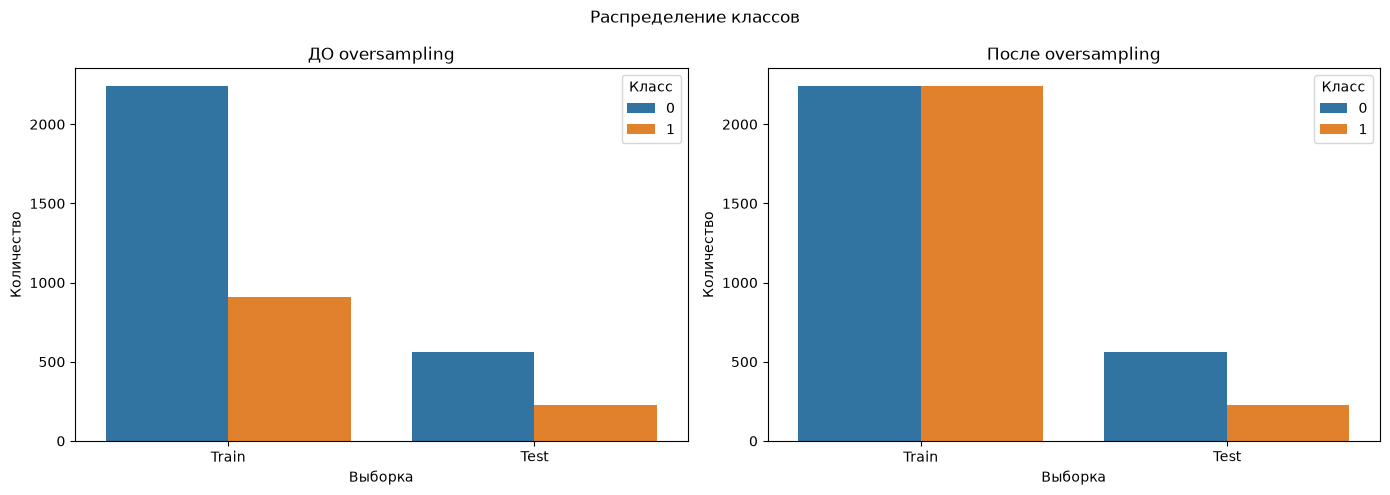

In [317]:
plot_df = pd.concat([
    y_train.value_counts().rename('Количество').to_frame().assign(Выборка='Train'),
    y_test.value_counts().rename('Количество').to_frame().assign(Выборка='Test')
]).reset_index(names='Класс')
plot_df_resampled = pd.concat([
    y_train_resampled.value_counts().rename('Количество').to_frame().assign(Выборка='Train'),
    y_test.value_counts().rename('Количество').to_frame().assign(Выборка='Test')
]).reset_index(names='Класс')

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(plot_df, x='Выборка', y='Количество', hue='Класс', ax=ax1)
ax1.set_title('ДО oversampling')
sns.barplot(plot_df_resampled, x='Выборка', y='Количество', hue='Класс', ax=ax2)
ax2.set_title('После oversampling')
fig.suptitle('Распределение классов')
plt.tight_layout()
plt.show()

### 10. Из  библиотеки  sklearn.neighbors возьмите  алгоритм  классификации  KNN (KNeighborsClassifier). 

Постройте (обучите) модель. Для параметров используйте значения по умолчанию.

In [318]:
neigh = KNeighborsClassifier()
neigh.fit(X_train_resampled, y_train_resampled)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


### 11. Из библиотеки sklearn.tree возьмите алгоритм классификации на основе деревьев решений  (DecisionTreeClassifier).

Постройте (обучите) модель. Для параметров используйте значения по умолчанию. 

In [319]:
dtc = DecisionTreeClassifier(random_state=RANDOM_STATE)
dtc.fit(X_train_resampled, y_train_resampled)

,"random_state random_state: int, RandomState instance or None, default=NoneControls the randomness of the estimator. The features are alwaysrandomly permuted at each split, even if ``splitter`` is set to``""best""``. When ``max_features < n_features``, the algorithm willselect ``max_features`` at random at each split before finding the bestsplit among them. But the best found split may vary across differentruns, even if ``max_features=n_features``. That is the case, if theimprovement of the criterion is identical for several splits and onesplit has to be selected at random. To obtain a deterministic behaviourduring fitting, ``random_state`` has to be fixed to an integer.See :term:`Glossary <random_state>` for details.",42
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.",'gini'
,"splitter splitter: {""best"", ""random""}, default=""best""The strategy used to choose the split at each node. Supportedstrategies are ""best"" to choose the best split and ""random"" to choosethe best random split among considered features for this split.",'best'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: int, float or {""sqrt"", ""log2""}, default=NoneThe number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`.Note: splitting may inspect more than ``max_features`` features ifneeded to find a valid split.",None
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow a tree with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples

### 12. Получите векторы прогнозных значений целевой переменной на обучающей и на тестовой выборках для каждой из моделей.

In [320]:
neigh_y_pred_train = neigh.predict(X_train_resampled)
neigh_y_pred_test = neigh.predict(X_test)
dtc_y_pred_train = dtc.predict(X_train_resampled)
dtc_y_pred_test = dtc.predict(X_test)

### 13. Посчитайте показатели качества: «F-мера», точность (Precision) и полнота (Recall) на обучающей и на тестовой выборках для каждой из моделей. 

In [321]:
reports = {'neigh_train': {}, 'neigh_test': {}, 'dtc_train': {}, 'dtc_test': {}}
preds = {'neigh_train': neigh_y_pred_train, 'neigh_test': neigh_y_pred_test, 'dtc_train': dtc_y_pred_train, 'dtc_test': dtc_y_pred_test}
ndigits = 3
for report_name in reports:
    selection = report_name.split('_')[1]
    report_metrics = {'precision': None, 'recall': None, 'f1': None}
    if selection == 'train':
        report_metrics['precision'] = round(precision_score(y_train_resampled, preds[report_name]), ndigits)
        report_metrics['recall'] = round(recall_score(y_train_resampled, preds[report_name]), ndigits)
        report_metrics['f1'] = round(f1_score(y_train_resampled, preds[report_name]), ndigits)
    if selection == 'test':
        report_metrics['precision'] = round(precision_score(y_test, preds[report_name]), ndigits)
        report_metrics['recall'] = round(recall_score(y_test, preds[report_name]), ndigits)
        report_metrics['f1'] = round(f1_score(y_test, preds[report_name]), ndigits)
    reports[report_name] = report_metrics

### 14. Сделайте  вывод  о  том,  насколько  хорошо  удалось  решить  задачу прогнозирования.

Какая  модель  оказалась  лучше?  Дайте  интерпретацию полученных значений Precision и Recall. 

In [322]:
print(json.dumps(reports, indent=4))

{
    "neigh_train": {
        "precision": 0.877,
        "recall": 0.944,
        "f1": 0.909
    },
    "neigh_test": {
        "precision": 0.678,
        "recall": 0.811,
        "f1": 0.739
    },
    "dtc_train": {
        "precision": 1.0,
        "recall": 1.0,
        "f1": 1.0
    },
    "dtc_test": {
        "precision": 0.762,
        "recall": 0.759,
        "f1": 0.76
    }
}


Обе модели показали переобучение.

На тестовой части модели показали хорошие результаты, однако есть некоторые различия:

`Precision`:
1. DecisionTreeClassifier - 0.762
2. KNeighborsClassifier - 0.678

`Recall`:
1. KNeighborsClassifier - 0.811
2. DecisionTreeClassifier - 0.759

Модель имеющая высокое качество метрики `Precision` позволит компании, возможно, более пессимистично, но точно расчитывать на продажу после бронирования (если модель показала 'Продана', то квартира с большой вероятностью действительно будет продана).

При выборе модели с высокой метрикой `Recall` можно столкнуться с существенными расхождениями прогноза и реального результата. Она найдет большую часть бронирований, которые действительно завершаться договором, но также может ошибочно отнести к успешным и те бронирования, которые будут отменены.

Все зависит от текущей политики компании: снизить риск завышения ожидаемых продаж - `Precision`, выявить как можно больше потенциальных продаж - `Recall`.

---
При стандартном пороге принятия решения (decision thrashold) = 0.5:

Для снижения риска лучше использовать модель: `DecisionTreeClassifier` (Precision = 0.762)

Для выявления потенциальных продаж модель: `KNeighborsClassifier` (Recall = 0.811)

## Дополнительное задание

### 15. Выполните подбор параметров для алгоритмов KNN и деревьев решений.

Для KNN попробуйте изменять параметр k  –  количество соседей, для деревьев решений – глубину  дерева. 

Постройте  графики  зависимости  показателей  качества  от значения параметра (от k  в случае KNN  и от глубины дерева в случае деревьев решений).

Для параметра k  рассматривайте диапазон от 1 до 40. Для глубины дерева – от 2 до 40.

По графикам определите оптимальные значения параметров.